# 02 · Manifold — principal-curve trajectory (whole malignant compartment)

The Gate-1 analysis established the topology to fit here. Unlike Kürten (an
elongated embryonic *lobe* scoped out of a cycling compartment), the Chen manifold
does **not** resolve into a clean lobe split: low-resolution Leiden gives several
balanced sub-regions, and the gastrulation program is **anti-correlated** with
cycling (the opposite of a proliferation-confounded lobe), so no sub-region needs
to be scoped out. We therefore fit the **whole** malignant manifold, Puram-style.

**Topology is non-branching.** The developmental signal is a single monotone axis
(the major UMAP axis correlates Gast +0.75 / Crest -0.77), the two embryonic
programs do **not** cross-repress (smoothed Gast~pSom ~= 0), and a PPT tree's tips
land on technical clusters (Ribosomal / Proliferative / Metabolic), not distinct
developmental termini. The correct object is a **principal curve** (scFates
`curve`, non-branching by construction), fit on the joint `X_umap` coordinates
(**no re-embedding** of the compartment — that fabricates folds). A fold-free
diagnostic (node self-approach ratio) and an explicit curve render certify the
backbone does not fold. Deliverable: `manifold.h5ad`, `manifold.pdf`.

In [1]:
import os, sys, glob, io, contextlib
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scFates as scf
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
from scipy.stats import spearmanr
import matplotlib.pyplot as plt
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4))
pth_data = os.path.join(pth, 'data', 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig  = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_feat = os.path.join(pth, 'data', 'features', 'biomart')
os.makedirs(pth_fig, exist_ok=True)
print('dataset:', name, '| category:', cat)

dataset: Chen2020_Head-and-Neck-5 | category: Head-and-Neck


### Load the processed manifold
Cells stay on their joint `X_umap` coordinates from step 01 — no re-embedding.

cells: 3635 | samples: 8
UMAP aspect ratio (major/minor std): 1.39  (roundish cloud; cell-cycle spreads it orthogonally to the developmental axis)


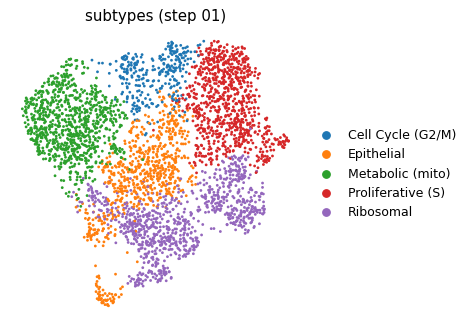

In [3]:
adata = sc.read_h5ad(os.path.join(pth_data, 'processed.h5ad'))
xy = adata.obsm['X_umap']
c = xy - xy.mean(0); s = np.linalg.svd(c, full_matrices=False)[1]
print('cells:', adata.n_obs, '| samples:', adata.obs['sample'].nunique())
print(f'UMAP aspect ratio (major/minor std): {s[0]/s[1]:.2f}  '
      '(roundish cloud; cell-cycle spreads it orthogonally to the developmental axis)')
fig, ax = plt.subplots(1, 1, figsize=(4.2, 4.2))
sc.pl.umap(adata, color='subtype', size=20, frameon=False, show=False, ax=ax, title='subtypes (step 01)')

### Score the three embryonic modules and graph-smooth them
Scored against the shared **union** control pool, then graph-smoothed
(knn-connectivity averaging) so the root is read off *geography*, not single-cell
dropout — the 10x precedent (Kürten). Full signature UMAPs are the step-03
deliverable; here the smoothed scores are used only to derive the root.

In [4]:
def load_set(fn):
    df = pd.read_csv(os.path.join(pth_feat, fn))
    col = 'hsapiens' if 'hsapiens' in df.columns else df.columns[0]
    g = df[col].dropna().astype(str).str.strip()
    return sorted(set(g[g != '']))
sets = {'Gast': 'GSE162534.csv', 'pSom': 'GSE229103.csv', 'Crest': 'rRNAModifications.csv'}
pool = [g for g in load_set('union.csv') if g in adata.var_names]
for lab, fn in sets.items():
    g = [x for x in load_set(fn) if x in adata.var_names]
    sc.tl.score_genes(adata, g, ctrl_size=50, gene_pool=pool, score_name=lab, random_state=1234)
    print(f'{lab}: {len(g)} genes present')
# graph-smooth (3 propagations over the knn connectivity graph)
A = (adata.obsp['connectivities'] > 0).astype(float) + sp.eye(adata.n_obs)
A = sp.diags(1 / np.asarray(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast', 'pSom', 'Crest']].values.copy()
for _ in range(3): S = A @ S
for j, lab in enumerate(['Gast', 'pSom', 'Crest']): adata.obs[lab + '_sm'] = S[:, j]
print('smoothed Gast~pSom corr = %.2f (near-zero -> no cross-repression -> non-branching)'
      % np.corrcoef(adata.obs.Gast_sm, adata.obs.pSom_sm)[0, 1])

Gast: 73 genes present
pSom: 91 genes present
Crest: 99 genes present
smoothed Gast~pSom corr = 0.00 (near-zero -> no cross-repression -> non-branching)


### Fit the principal curve (non-branching)
`scFates.tl.curve` (ElPiGraph) is non-branching by construction. `epg_mu=100` is
strong bending regularisation, keeping the backbone a smooth arc through the cloud
rather than a kinked path that would assign near-neighbour cells divergent
pseudotime.

In [5]:
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(adata, Nodes=20, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0,
                 seed=SEED, plot=False)
print('principal curve fit (Nodes=20)')

principal curve fit (Nodes=20)


### Fold-free / branch-free topology check (shown, not asserted)
The **self-approach ratio** = minimum distance between graph-non-adjacent nodes,
in units of median edge length; > 1 certifies the backbone does not fold back on
itself. The curve is rendered over the embedding so a reviewer sees the topology
directly (the attempt-6 failure mode: a fold invisible to a colour-only panel).

curve: 2 tips, 0 forks | fold self-approach ratio = 2.80 (>1 = fold-free)


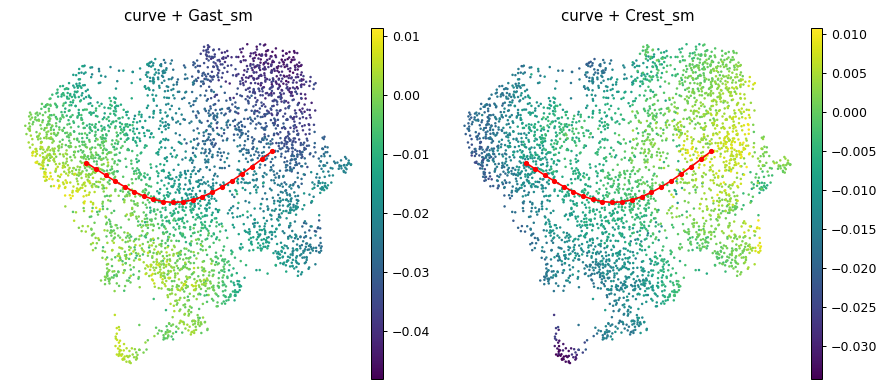

In [6]:
def topo_diag(ad):
    B = np.asarray(ad.uns['graph']['B']); F = ad.uns['graph']['F'].T
    G = shortest_path(sp.csr_matrix((B > 0).astype(int)), unweighted=True)
    ii, jj = np.where(np.triu(B > 0)); med = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin = np.inf
    for a in range(F.shape[0]):
        for b in range(a+1, F.shape[0]):
            if G[a, b] >= 3: dmin = min(dmin, np.sqrt(((F[a]-F[b])**2).sum()))
    return dmin/med, int(((B > 0).sum(0) == 1).sum()), int(((B > 0).sum(0) >= 3).sum())
sa, tips, forks = topo_diag(adata)
print(f'curve: {tips} tips, {forks} forks | fold self-approach ratio = {sa:.2f} (>1 = fold-free)')
assert forks == 0 and sa > 1, 'topology check failed'

# render the fitted curve edges over the embedding
B = np.asarray(adata.uns['graph']['B']); F = adata.uns['graph']['F'].T
fig, axes = plt.subplots(1, 2, figsize=(10, 4.4))
for ax, col, cm in [(axes[0], 'Gast_sm', 'viridis'), (axes[1], 'Crest_sm', 'viridis')]:
    sc.pl.umap(adata, color=col, size=16, cmap=cm, frameon=False, show=False, ax=ax, title=f'curve + {col}')
    ii, jj = np.where(np.triu(B > 0))
    for a, b in zip(ii, jj): ax.plot([F[a,0],F[b,0]], [F[a,1],F[b,1]], '-', c='red', lw=1.3, zorder=10)
    ax.scatter(F[:,0], F[:,1], c='red', s=10, zorder=11)
fig.tight_layout()

### Root at the developmental origin and infer pseudotime
The root is set data-driven to the curve tip with the highest Gast+pSom and lowest
Crest — the gastrulation/somitogenesis origin. Neural crest is developmentally
*late*, so it must be the terminus, not the root (the Kürten root error).

In [7]:
B = np.asarray(adata.uns['graph']['B']); tps = np.where((B > 0).sum(0) == 1)[0]
R = np.asarray(adata.obsm['X_R']); hard = R.argmax(1)
D = shortest_path(sp.csr_matrix((B > 0).astype(int)), unweighted=True)
info = {}
for t in tps:
    m = np.isin(hard, np.where(D[t] <= 3)[0])
    info[t] = (adata.obs.Gast_sm[m].mean(), adata.obs.pSom_sm[m].mean(), adata.obs.Crest_sm[m].mean())
    print(f'tip {t}: Gast={info[t][0]:+.4f} pSom={info[t][1]:+.4f} Crest={info[t][2]:+.4f}')
root = int(max(tps, key=lambda t: info[t][0] + info[t][1] - info[t][2]))
print('derived root = tip', root, '(Gast/pSom-high, Crest-low developmental origin)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(adata, root); scf.tl.pseudotime(adata, n_map=1, seed=SEED)
t = adata.obs['t'].values
print('\npseudotime gradient (Spearman rho, root = developmental origin):')
for lab in ['Gast_sm', 'pSom_sm', 'Crest_sm']:
    rho, p = spearmanr(t, adata.obs[lab]); print(f'  {lab}: rho={rho:+.3f} p={p:.1e}')
print('\n-> Gast/pSom high at origin, Crest the inverse/terminal gradient: NON-BRANCHING pattern')

tip 0: Gast=-0.0045 pSom=+0.0022 Crest=-0.0135
tip 2: Gast=-0.0308 pSom=-0.0004 Crest=+0.0019
derived root = tip 0 (Gast/pSom-high, Crest-low developmental origin)

pseudotime gradient (Spearman rho, root = developmental origin):
  Gast_sm: rho=-0.785 p=0.0e+00
  pSom_sm: rho=-0.214 p=4.4e-39
  Crest_sm: rho=+0.816 p=0.0e+00

-> Gast/pSom high at origin, Crest the inverse/terminal gradient: NON-BRANCHING pattern


### Rename milestones and orient to house style
Milestones are named by their signature identity (Embryonic origin -> Crest
terminus). House style puts low pseudotime on the **left**; the raw embedding
already satisfies this (corr(raw_x, pseudotime) = +0.96), so we keep raw
coordinates — no swap/rotation is applied (reorienting a near-horizontal axis
would be gratuitous and risks a silent reflection).

In [8]:
mask_root = adata.obs['t'] <= np.percentile(adata.obs['t'], 15)
mask_term = adata.obs['t'] >= np.percentile(adata.obs['t'], 85)
mst = {str(int(root)): 'Embryonic_origin'}
term_tip = int([x for x in tps if x != root][0])
mst[str(term_tip)] = 'Crest_terminus'
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.rename_milestones(adata, new=mst)
xy = adata.obsm['X_umap']; t = adata.obs['t'].values
r = float(np.corrcoef(xy[:, 0], t)[0, 1])
assert r > 0, f'pseudotime not left->right (corr={r:+.2f})'
adata.obsm['X_umap_lin'] = xy.copy()
print('milestones:', list(adata.obs['milestones'].cat.categories))
print(f'orientation: raw coords kept; corr(x, pseudotime) = {r:+.2f} (low-t left -> high-t right)')

milestones: ['Embryonic_origin', 'Crest_terminus']
orientation: raw coords kept; corr(x, pseudotime) = +0.96 (low-t left -> high-t right)


### Save manifold + trajectory figure (deliverable)
Reference (Puram) layout: a single square UMAP of the whole manifold coloured by
**pseudotime** (cividis), milestone labels on data, external colorbar.

saved manifold.h5ad (3635, 22080)
saved manifold.pdf
saved colorbars/pseudotime_colorbar.pdf


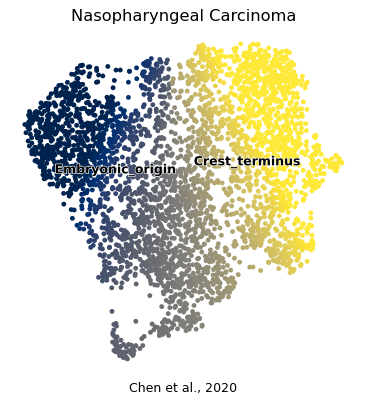

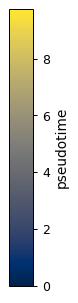

In [9]:
# sanitize non-serializable ElPiGraph uns entry before writing
adata.uns['epg'] = {'NodePositions': np.asarray(adata.uns['epg']['NodePositions'])}
adata.write(os.path.join(pth_data, 'manifold.h5ad'))
print('saved manifold.h5ad', adata.shape)

fig, ax = plt.subplots(1, 1, figsize=(5, 5))
sc.pl.umap(adata, color='t', cmap='cividis', size=60, colorbar_loc=None,
           frameon=False, show=False, ax=ax)
sc.pl.umap(adata, color='milestones', size=60, alpha=0, legend_loc='on data',
           legend_fontoutline=1, frameon=False, show=False, ax=ax)
ax.set_title('Nasopharyngeal Carcinoma', size=13)
ax.text(.5, -.05, 'Chen et al., 2020', ha='center', transform=ax.transAxes)
fig.savefig(os.path.join(pth_fig, 'manifold.pdf'), bbox_inches='tight')
print('saved manifold.pdf')

# external pseudotime colorbar (house style: colorbars live in colorbars/)
import matplotlib as mpl
os.makedirs(os.path.join(pth_fig, 'colorbars'), exist_ok=True)
figc, axc = plt.subplots(figsize=(0.35, 4))
norm = mpl.colors.Normalize(vmin=float(t.min()), vmax=float(t.max()))
mpl.colorbar.ColorbarBase(axc, cmap=plt.get_cmap('cividis'), norm=norm).set_label('pseudotime', size=11)
figc.savefig(os.path.join(pth_fig, 'colorbars', 'pseudotime_colorbar.pdf'), bbox_inches='tight')
print('saved colorbars/pseudotime_colorbar.pdf')